# Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from sklearn.model_selection import train_test_split, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# **Μέρος ΙΙ: Πρόβλεψη Σκορ Κούρασης (next_day_fatigue_score)**

Επαναλαμβάνουμε το Μέρος Ι, αλλά τώρα το target είναι η next_day_fatigue_score (συνεχής μεταβλητή)

# **1. Load Dataset - Data**

In [2]:
df = pd.read_csv('sleep.csv')
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,USR-08496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt
8496,USR-08497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt
8497,USR-08498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit
8498,USR-08499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt


## Περιγραφή Μεταβλητών

Οι μεταβλητές είναι ίδιες με το Μέρος Ι. Εδώ μας ενδιαφέρει:

*   **next_day_fatigue_score** : Σκορ κούρασης την επόμενη ημέρα, από 1 (καθόλου κούραση) έως 10 (πολύ μεγάλη κούραση). Είναι το target.

## Ιστογράμματα Χαρακτηριστικών

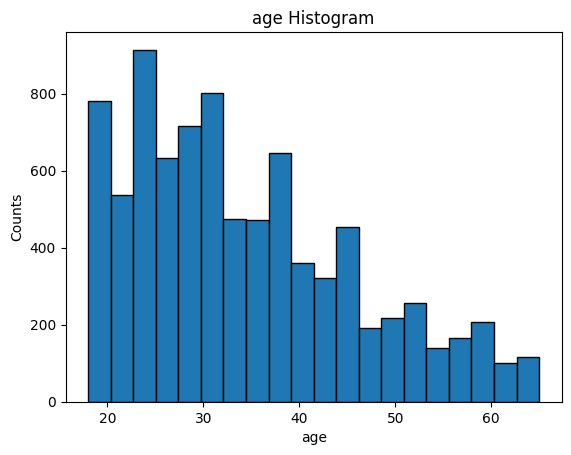

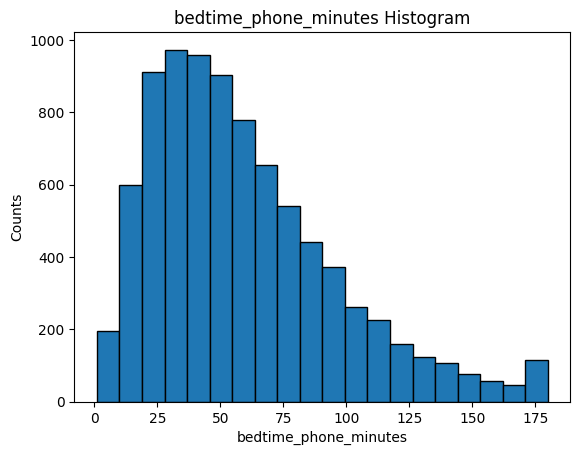

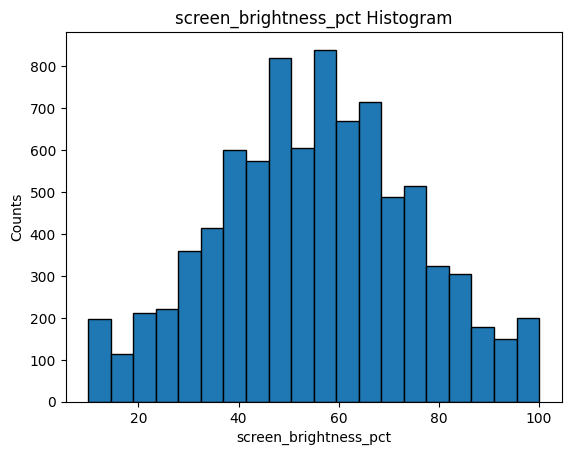

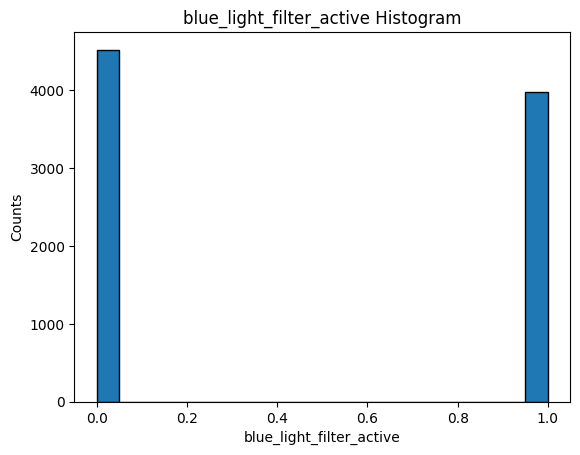

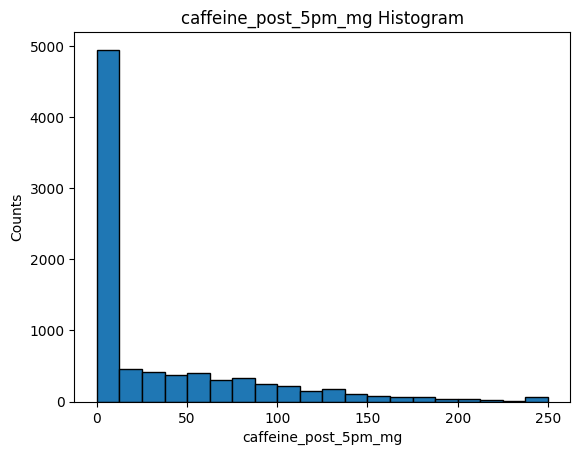

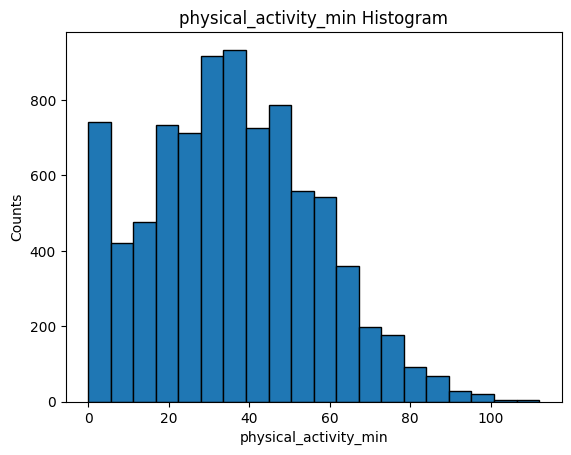

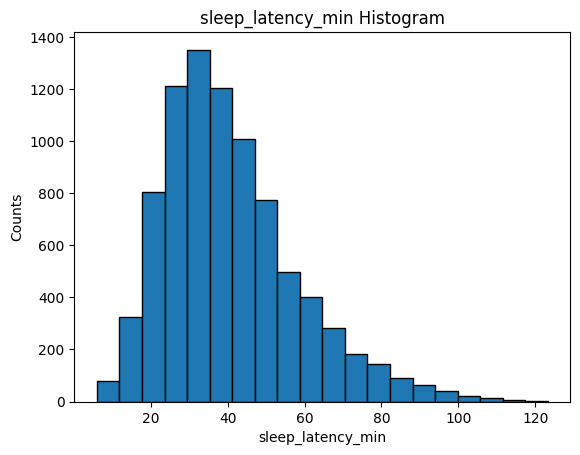

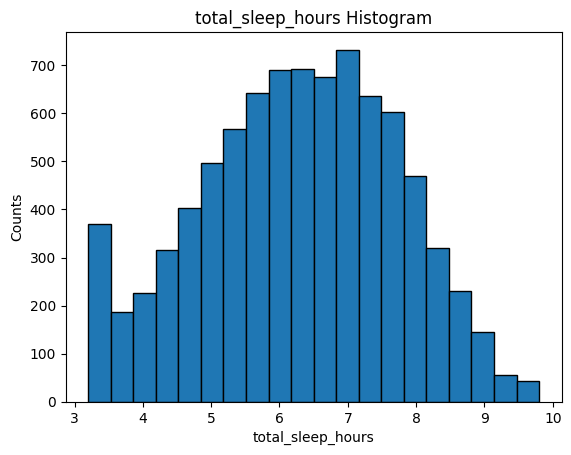

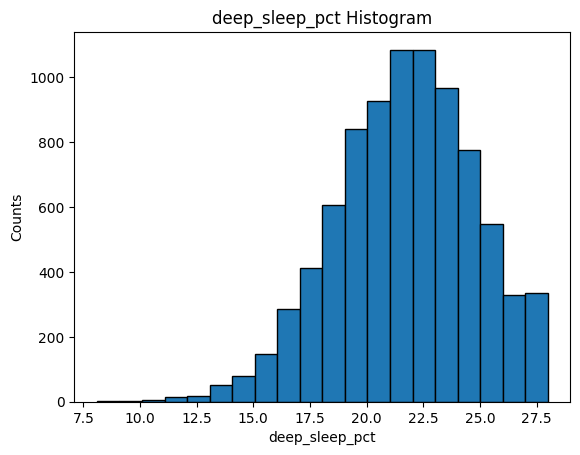

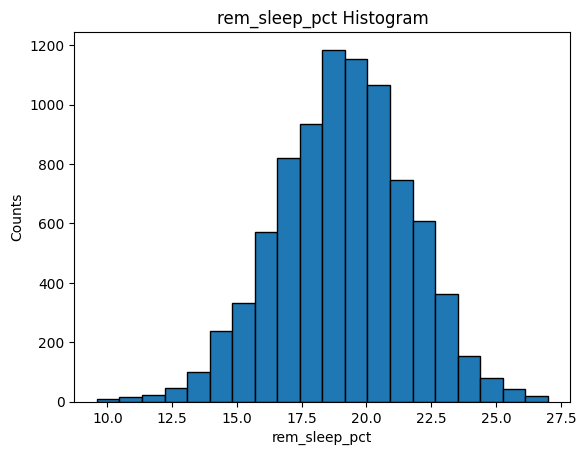

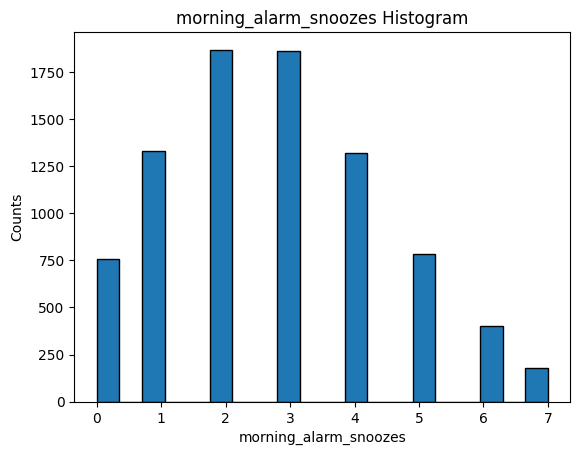

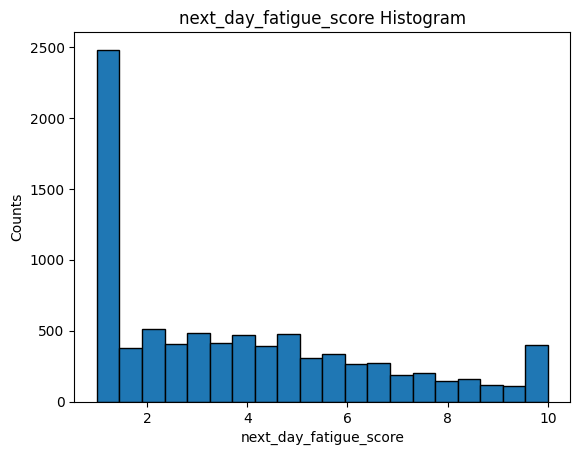

In [3]:
numeric_cols = ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active',
                'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours',
                'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score']

for col in numeric_cols:
    df[col].hist(bins=20, edgecolor='black')
    plt.title(f'{col} Histogram')
    plt.xlabel(col)
    plt.ylabel('Counts')
    plt.grid(False)
    plt.show()

## Ραβδογράμματα Κατηγορικών Μεταβλητών

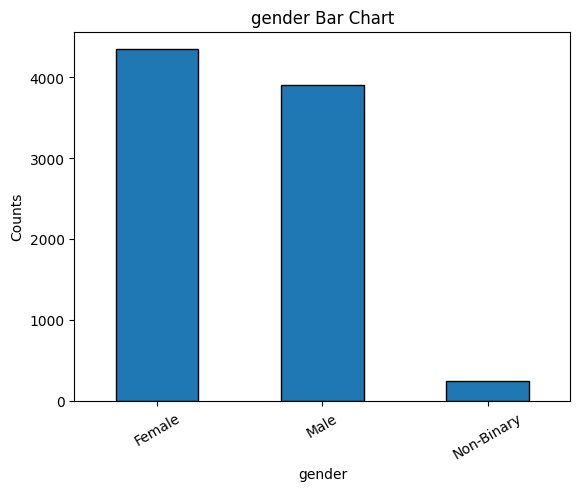

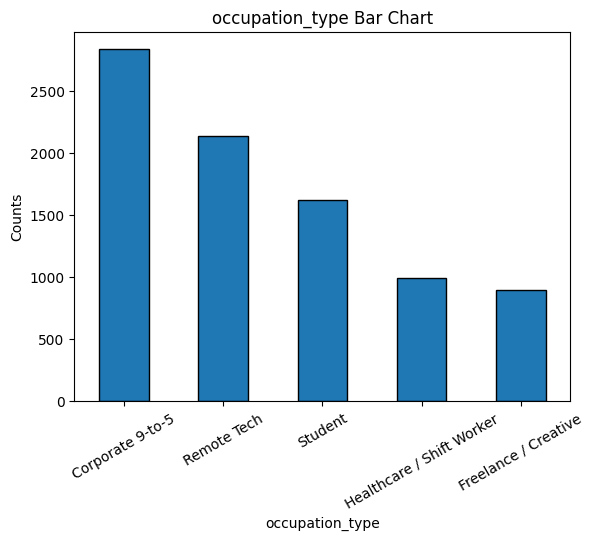

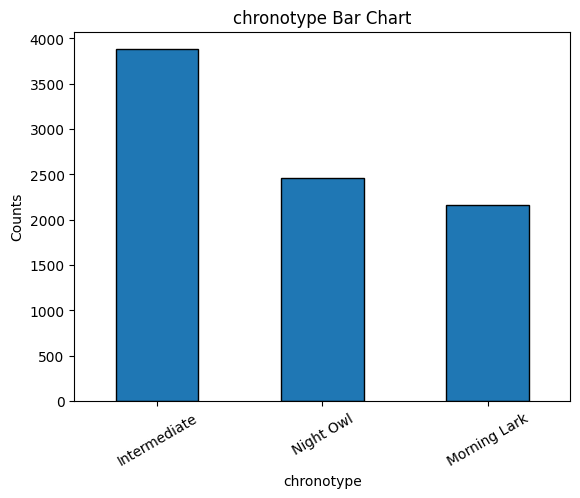

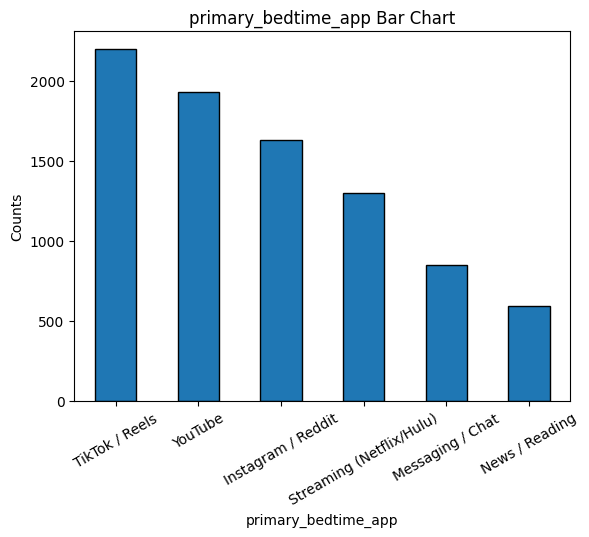

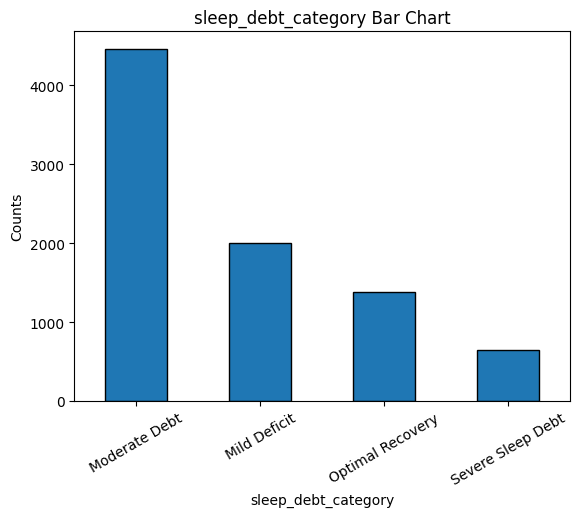

In [4]:
categorical_cols = ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app', 'sleep_debt_category']

for col in categorical_cols:
    df[col].value_counts().plot(kind='bar', edgecolor='black')
    plt.title(f'{col} Bar Chart')
    plt.xlabel(col)
    plt.ylabel('Counts')
    plt.xticks(rotation=30)
    plt.grid(False)
    plt.show()

## Κατανομή του Target (next_day_fatigue_score)

Σε παλινδρόμηση δεν υπάρχουν κλάσεις, οπότε κοιτάμε πώς κατανέμονται οι τιμές του target.

In [5]:
fatigue = df['next_day_fatigue_score']

print(f'Mean: {fatigue.mean():.2f}, Median: {fatigue.median():.2f}, Std: {fatigue.std():.2f}')
print(f'Ποσοστό με σκορ = 1 (ελάχιστο): {(fatigue == 1).mean()*100:.2f}%')
print(f'Ποσοστό με σκορ = 10 (μέγιστο): {(fatigue == 10).mean()*100:.2f}%')

Mean: 3.79, Median: 3.20, Std: 2.69
Ποσοστό με σκορ = 1 (ελάχιστο): 24.82%
Ποσοστό με σκορ = 10 (μέγιστο): 3.69%


## Παρατηρήσεις

- Το σκορ κούρασης παίρνει τιμές από 1 έως 10, με μέση τιμή 3.79 και διάμεσο 3.20.
- Η κατανομή είναι **ασύμμετρη προς τα δεξιά**: περίπου το 25% των χρηστών έχει το ελάχιστο σκορ (1.0), ενώ λίγοι (3.7%) φτάνουν στο μέγιστο (10.0).
- Η ασυμμετρία σημαίνει ότι το μοντέλο θα βλέπει λιγότερα παραδείγματα με μεγάλη κούραση και πιθανόν να κάνει μεγαλύτερα λάθη εκεί.

# **2. Αφαίρεση μεταβλητής sleep_debt_category**

Αφαιρούμε τη sleep_debt_category

In [9]:
df_reg = df.drop(columns=['sleep_debt_category', 'user_id'])
df_reg

,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
0,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0
1,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0
2,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0
3,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7
4,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2
8496,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0
8497,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7
8498,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0


# **3. One-Hot Encoding**

Εφαρμόζουμε One-Hot Encoding στις κατηγορικές μεταβλητές εισόδου.

In [10]:
df_reg = pd.get_dummies(df_reg, columns=categorical_cols[:-1], dtype=int)
df_reg

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,occupation_type_Student,chronotype_Intermediate,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,...,0,1,0,0,1,0,0,0,0,0
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,...,1,1,0,0,0,0,0,0,0,1
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,...,0,0,0,1,0,0,0,0,1,0
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,...,0,1,0,0,0,0,0,0,0,1
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,...,0,1,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,61,18,61,1,60,74,21.0,5.57,26.5,18.1,...,0,0,0,1,0,0,0,1,0,0
8496,64,138,58,1,0,58,84.3,3.99,20.4,19.4,...,1,0,0,1,0,0,0,0,1,0
8497,34,56,56,0,94,33,40.6,7.58,17.4,20.7,...,0,1,0,0,0,0,0,1,0,0
8498,23,165,72,0,0,52,123.3,3.20,14.2,15.8,...,0,0,0,1,0,0,0,0,1,0


# **4. Numpy Arrays and Train - Validation - Test Datasets**

In [11]:
input_df = df_reg.drop(columns=['next_day_fatigue_score'])
targets_df = df_reg['next_day_fatigue_score']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((8500, 28), (8500,))

## Διαχωρισμός Train - Validation - Test Dataset

Ποσοστά 70-20-10 με seed = 0. Δε χρησιμοποιούμε stratify. Ο διαχωρισμός γίνεται τυχαία.

In [12]:
seed = 0
test_size = 0.1
valid_size = 0.2 / (1 - test_size)

x_train_full, x_test, y_train_full, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train, x_valid, y_train, y_valid = train_test_split(x_train_full, y_train_full, test_size=valid_size, random_state=seed)

x_train.shape, x_valid.shape, x_test.shape

((5949, 28), (1701, 28), (850, 28))

In [13]:
print(f'Number of training samples: {x_train.shape[0]}')
print(f'Number of validation samples: {x_valid.shape[0]}')
print(f'Number of test samples: {x_test.shape[0]}')

Number of training samples: 5949
Number of validation samples: 1701
Number of test samples: 850


Αφού ο διαχωρισμός είναι τυχαίος, ελέγχουμε ότι το target έχει παρόμοια κατανομή σε κάθε σύνολο.

In [14]:
pd.DataFrame({
    'Train': pd.Series(y_train).describe(),
    'Validation': pd.Series(y_valid).describe(),
    'Test': pd.Series(y_test).describe()
}).loc[['mean', 'std', 'min', '50%', 'max']].round(2)

,Train,Validation,Test
mean,3.81,3.75,3.80
std,2.68,2.70,2.72
min,1.00,1.00,1.00
50%,3.30,3.10,3.20
max,10.00,10.00,10.00


# **5. KNN Regressor - Βελτιστοποίηση Υπερπαραμέτρων (Train - Validation)**

In [15]:
metric_names = ['MAE', 'RMSE', 'R2']
weight_values = ['uniform', 'distance']
selection_metric = 'RMSE'


def evaluate(y_true, y_pred):
    return {
        'MAE': round(mean_absolute_error(y_true, y_pred), 4),
        'RMSE': round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        'R2': round(r2_score(y_true, y_pred), 4)
    }


def train_knn(x_train, y_train, k, weights):
    scaler = StandardScaler()
    scaler.fit(x_train)
    model = KNeighborsRegressor(n_neighbors=k, weights=weights)
    model.fit(scaler.transform(x_train), y_train)
    return model, scaler


def get_k_values(n_train):
    return [3, 5, 15, 50, n_train]

## Train model on training set - Evaluate on train and validation set

Για κάθε συνδυασμό k = {3, 5, 15, 50, n} και weights = {uniform, distance}, εκπαιδεύουμε τον KNN στο train και τον αξιολογούμε στο train και στο validation.

In [16]:
holdout_results = []

for k in get_k_values(len(x_train)):
    for weights in weight_values:
        model, scaler = train_knn(x_train, y_train, k, weights)

        train_scores = evaluate(y_train, model.predict(scaler.transform(x_train)))
        valid_scores = evaluate(y_valid, model.predict(scaler.transform(x_valid)))

        holdout_results.append({'k': k, 'weights': weights, 'Set': 'Train', **train_scores})
        holdout_results.append({'k': k, 'weights': weights, 'Set': 'Validation', **valid_scores})

holdout_results_df = pd.DataFrame(holdout_results)

## Πίνακας Αποτελεσμάτων Train

In [17]:
holdout_results_df[holdout_results_df['Set'] == 'Train'].drop(columns=['Set']).set_index(['k', 'weights'])

MAE    RMSE      R2
k    weights                         
3    uniform   0.6311  0.8625  0.8961
     distance  0.0000  0.0000  1.0000
5    uniform   0.7080  0.9461  0.8749
     distance  0.0000  0.0000  1.0000
15   uniform   0.8423  1.0759  0.8383
     distance  0.0000  0.0000  1.0000
50   uniform   0.9263  1.1578  0.8127
     distance  0.0000  0.0000  1.0000
5949 uniform   2.2467  2.6755  0.0000
     distance  0.0001  0.0001  1.0000

## Πίνακας Αποτελεσμάτων Validation

In [18]:
valid_results_df = holdout_results_df[holdout_results_df['Set'] == 'Validation'].drop(columns=['Set'])
valid_results_df.set_index(['k', 'weights'])

MAE    RMSE      R2
k    weights                         
3    uniform   0.8771  1.1886  0.8065
     distance  0.8677  1.1781  0.8099
5    uniform   0.8618  1.1486  0.8193
     distance  0.8502  1.1342  0.8238
15   uniform   0.8900  1.1363  0.8232
     distance  0.8743  1.1190  0.8285
50   uniform   0.9341  1.1653  0.8141
     distance  0.9214  1.1511  0.8185
5949 uniform   2.2541  2.7029 -0.0004
     distance  2.1215  2.5565  0.1050

## Καλύτερος Συνδυασμός Παραμέτρων

In [19]:
best_row = valid_results_df.loc[valid_results_df[selection_metric].idxmin()]
best_k, best_weights = int(best_row['k']), best_row['weights']

print(f'Best combination (by validation {selection_metric}): k = {best_k}, weights = {best_weights}')

Best combination (by validation RMSE): k = 15, weights = distance


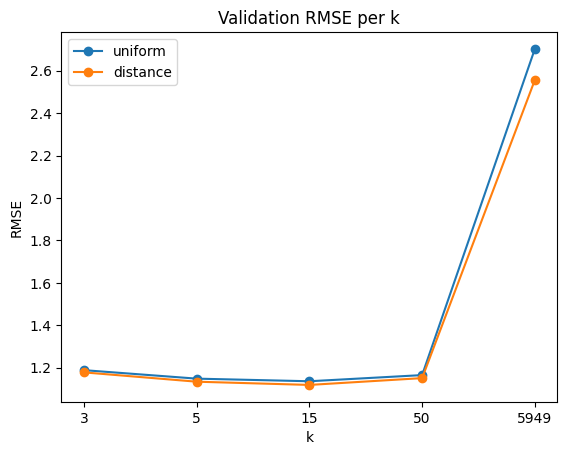

In [20]:
for weights in weight_values:
    subset = valid_results_df[valid_results_df['weights'] == weights]
    plt.plot([str(k) for k in subset['k']], subset[selection_metric], marker='o', label=weights)
plt.title('Validation RMSE per k')
plt.xlabel('k')
plt.ylabel('RMSE')
plt.legend()
plt.grid(False)
plt.show()

## Παρατηρήσεις

- distance βάρη: το train σφάλμα είναι 0 (R² = 1), γιατί κάθε παράδειγμα του train βρίσκει τον εαυτό του με απόσταση 0, οπότε η αξιολόγηση στο train εδώ δε λέει κάτι.
- Μικρό k (3): μεγαλύτερο σφάλμα στο validation, γιατί η πρόβλεψη βασίζεται σε πολύ λίγους γείτονες και επηρεάζεται από τον θόρυβο (υψηλή διακύμανση).
- k = 5 έως 50: παρόμοια αποτελέσματα, με RMSE γύρω στο 1.12-1.17 και R² γύρω στο 0.82.
- k = n, uniform: προβλέπει πάντα τη μέση τιμή του train, άρα R² ≈ 0. Αυτό είναι ακριβώς το απλοϊκό μοντέλο με το οποίο συγκρίνει το R² (διαφάνεια 44).

Καλύτερος συνδυασμός με βάση το RMSE στο validation: k = 15 με distance.

# **6. Τελική Αξιολόγηση στο Test Set**

Ενώνουμε train και validation, ξανακάνουμε fit τον scaler στο νέο train set και εκπαιδεύουμε τον KNN με τον καλύτερο συνδυασμό.

In [21]:
model, scaler = train_knn(x_train_full, y_train_full, best_k, best_weights)

y_pred = model.predict(scaler.transform(x_test))
test_scores = evaluate(y_test, y_pred)

## Σύγκριση Train - Validation - Test

In [22]:
best_train_scores = holdout_results_df[(holdout_results_df['k'] == best_k) & (holdout_results_df['weights'] == best_weights) & (holdout_results_df['Set'] == 'Train')][metric_names].iloc[0]

comparison_df = pd.DataFrame([best_train_scores, best_row[metric_names], pd.Series(test_scores)],
                             index=['Train', 'Validation', 'Test'])
comparison_df

,MAE,RMSE,R2
Train,0.0000,0.000,1.0000
Validation,0.8743,1.119,0.8285
Test,0.8592,1.110,0.8329


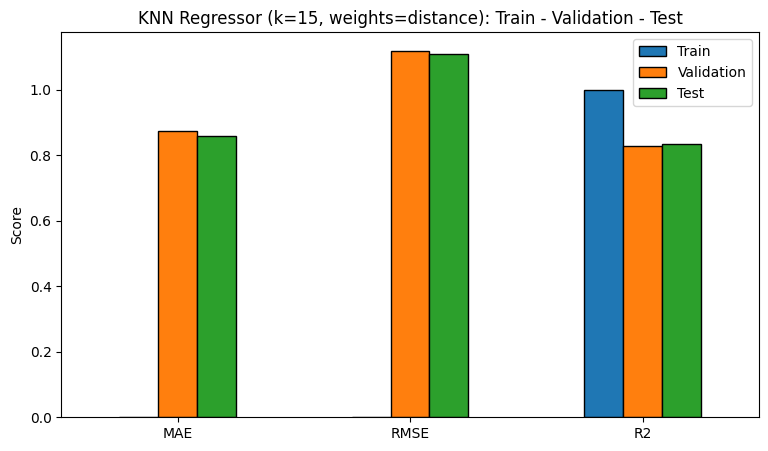

In [23]:
comparison_df.T.plot(kind='bar', edgecolor='black', figsize=(9, 5))
plt.title(f'KNN Regressor (k={best_k}, weights={best_weights}): Train - Validation - Test')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.grid(False)
plt.show()

## Παρατηρήσεις

- Το train έχει μηδενικό σφάλμα λόγω του distance, οπότε δεν μπορεί να χρησιμοποιηθεί για σύγκριση.
- Το test είναι πολύ κοντά στο validation. Αυτό εξηγείται γιατί το τελικό μοντέλο εκπαιδεύτηκε σε περισσότερα δεδομένα (train + validation).

# **7. Holdout + 5-Fold Cross Validation**

Χωρίζουμε σε train - test (90-10, seed = 0) και εφαρμόζουμε 5-Fold Cross Validation στο train για να βρούμε τις καλύτερες παραμέτρους.

In [25]:
def cross_validate_knn(x, y, n_splits=5):
    folds = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    fold_scores = []

    for fold, (train_idx, valid_idx) in enumerate(folds.split(x)):
        x_tr, x_val = x[train_idx], x[valid_idx]
        y_tr, y_val = y[train_idx], y[valid_idx]

        for k_index, k in enumerate(get_k_values(len(x_tr))):
            for weights in weight_values:
                model, scaler = train_knn(x_tr, y_tr, k, weights)
                scores = evaluate(y_val, model.predict(scaler.transform(x_val)))
                k_label = 'n' if k_index == 4 else k
                fold_scores.append({'fold': fold + 1, 'k': k_label, 'weights': weights, **scores})

    return pd.DataFrame(fold_scores)

## Διαχωρισμός Train - Test Dataset

In [26]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.1, random_state=seed)

print(f'Number of training samples: {x_train.shape[0]}')
print(f'Number of test samples: {x_test.shape[0]}')

Number of training samples: 7650
Number of test samples: 850


## Πίνακας Αποτελεσμάτων 5-Fold CV (μέσος όρος των folds)

In [27]:
cv_fold_scores = cross_validate_knn(x_train, y_train, n_splits=5)
cv_results_df = cv_fold_scores.groupby(['k', 'weights'], sort=False)[metric_names].mean().round(4)
cv_results_df

MAE    RMSE      R2
k  weights                         
3  uniform   0.8991  1.2155  0.7944
   distance  0.8899  1.2045  0.7980
5  uniform   0.8768  1.1653  0.8110
   distance  0.8652  1.1518  0.8153
15 uniform   0.8975  1.1490  0.8162
   distance  0.8822  1.1316  0.8217
50 uniform   0.9427  1.1787  0.8066
   distance  0.9292  1.1640  0.8114
n  uniform   2.2468  2.6816 -0.0003
   distance  2.1171  2.5378  0.1041

## Καλύτερος Συνδυασμός Παραμέτρων

In [29]:
best_k_label, best_weights = cv_results_df[selection_metric].idxmin()
best_k = len(x_train) if best_k_label == 'n' else best_k_label
print(f'Best combination (by mean CV {selection_metric}): k = {best_k_label}, weights = {best_weights}')

best_fold_scores = cv_fold_scores[(cv_fold_scores['k'] == best_k_label) & (cv_fold_scores['weights'] == best_weights)]
best_fold_scores

Best combination (by mean CV RMSE): k = 15, weights = distance


,fold,k,weights,MAE,RMSE,R2
5,1,15,distance,0.8707,1.1152,0.8320
15,2,15,distance,0.8716,1.1119,0.8236
25,3,15,distance,0.8683,1.1271,0.8246
35,4,15,distance,0.9246,1.1778,0.8074
45,5,15,distance,0.8758,1.1260,0.8211


## Διάστημα Εμπιστοσύνης 95% (t-Distribution)

Ίδια διαδικασία με το Μέρος Ι

In [30]:
def confidence_interval(scores, confidence=0.95):
    n = len(scores)
    mean = np.mean(scores)
    std = np.std(scores, ddof=1)
    a = 1 - confidence
    t_critical = stats.t.ppf(1 - a/2, df=n-1)
    e = t_critical * std / np.sqrt(n)
    return mean, std, mean - e, mean + e

In [31]:
ci_rows = []
for metric in metric_names:
    mean, std, low, high = confidence_interval(best_fold_scores[metric].to_numpy())
    ci_rows.append({'Metric': metric, 'Mean': mean, 'Std': std, 'CI Low': low, 'CI High': high})

ci_df = pd.DataFrame(ci_rows).set_index('Metric').round(4)
ci_df

,Mean,Std,CI Low,CI High
Metric,,,,
MAE,0.8822,0.0239,0.8526,0.9118
RMSE,1.1316,0.0267,1.0985,1.1647
R2,0.8217,0.0090,0.8106,0.8329


## Evaluate Model on test set

In [34]:
model, scaler = train_knn(x_train, y_train, best_k, best_weights)
cv_test_scores = evaluate(y_test, model.predict(scaler.transform(x_test)))

pd.DataFrame([ci_df['Mean'], pd.Series(cv_test_scores)], index=['5-Fold CV (mean)', 'Test'])

,MAE,RMSE,R2
5-Fold CV (mean),0.8822,1.1316,0.8217
Test,0.8592,1.1100,0.8329


## Παρατηρήσεις

- Με το Cross Validation ο καλύτερος συνδυασμός είναι πάλι k = 15 με distance, ίδιος με το Extended Holdout.
- Επειδή και οι δύο μέθοδοι κρατούν το ίδιο 10% για test (ίδιο seed, χωρίς stratify) και διάλεξαν τον ίδιο συνδυασμό, το τελικό μοντέλο και το test score είναι ακριβώς ίδια.
- Το RMSE στο test (1.11) πέφτει μέσα στο διάστημα εμπιστοσύνης [1.10, 1.16], άρα η εκτίμηση του CV ήταν αξιόπιστη.


# **8. Nested Cross Validation**

*   **Outer loop** : 3-Fold CV, κάθε outer fold παίζει ρόλο test set.
*   **Inner loop** : 5-Fold CV στο train του outer fold για να βρούμε τον καλύτερο συνδυασμό (k, weights).

Ο καλύτερος συνδυασμός εκπαιδεύεται σε όλο το outer train και αξιολογείται στο outer test. Η τελική απόδοση είναι ο μέσος όρος των 3 outer folds.

In [35]:
outer_folds = KFold(n_splits=3, shuffle=True, random_state=seed)
nested_results = []

for outer_fold, (train_idx, test_idx) in enumerate(outer_folds.split(x)):
    x_outer_train, x_outer_test = x[train_idx], x[test_idx]
    y_outer_train, y_outer_test = y[train_idx], y[test_idx]

    # Inner loop: βελτιστοποίηση υπερπαραμέτρων
    inner_scores = cross_validate_knn(x_outer_train, y_outer_train, n_splits=5)
    inner_results = inner_scores.groupby(['k', 'weights'], sort=False)[metric_names].mean()
    inner_k_label, inner_weights = inner_results[selection_metric].idxmin()
    inner_k = len(x_outer_train) if inner_k_label == 'n' else inner_k_label

    # Outer loop: αξιολόγηση του καλύτερου μοντέλου
    model, scaler = train_knn(x_outer_train, y_outer_train, inner_k, inner_weights)
    outer_scores = evaluate(y_outer_test, model.predict(scaler.transform(x_outer_test)))

    nested_results.append({'Outer Fold': outer_fold + 1, 'Best k': inner_k_label, 'Best weights': inner_weights, **outer_scores})
    print(f'Outer fold {outer_fold + 1}: k = {inner_k_label}, weights = {inner_weights} -> Test RMSE = {outer_scores[selection_metric]}')

Outer fold 1: k = 15, weights = distance -> Test RMSE = 1.145
Outer fold 2: k = 15, weights = distance -> Test RMSE = 1.1365
Outer fold 3: k = 15, weights = distance -> Test RMSE = 1.1543


## Πίνακας Αποτελεσμάτων Outer Folds

In [36]:
nested_results_df = pd.DataFrame(nested_results).set_index('Outer Fold')
nested_results_df

,Best k,Best weights,MAE,RMSE,R2
Outer Fold,,,,,
1,15,distance,0.8912,1.1450,0.8205
2,15,distance,0.8877,1.1365,0.8210
3,15,distance,0.9006,1.1543,0.8126


## Διάστημα Εμπιστοσύνης 95%

In [37]:
nested_ci_rows = []
for metric in metric_names:
    mean, std, low, high = confidence_interval(nested_results_df[metric].to_numpy())
    nested_ci_rows.append({'Metric': metric, 'Mean': mean, 'Std': std, 'CI Low': low, 'CI High': high})

nested_ci_df = pd.DataFrame(nested_ci_rows).set_index('Metric').round(4)
nested_ci_df

,Mean,Std,CI Low,CI High
Metric,,,,
MAE,0.8932,0.0067,0.8766,0.9097
RMSE,1.1453,0.0089,1.1232,1.1674
R2,0.8180,0.0047,0.8063,0.8297


## Παρατηρήσεις

- Και τα 3 outer folds διάλεξαν τον ίδιο συνδυασμό (k = 15 με distance), ίδιο με τις άλλες μεθόδους. Άρα η επιλογή του k = 15 είναι σταθερή.
- Το μέσο RMSE είναι 1.15 και το R² 0.82, λίγο χειρότερα από τις άλλες μεθόδους, γιατί εδώ τα δεδομένα δοκιμής δεν επηρεάζουν καθόλου την επιλογή των παραμέτρων, άρα η εκτίμηση είναι η πιο αμερόληπτη. Επίσης κάθε outer train έχει μόνο τα 2/3 των δεδομένων.


# **Σύγκριση Μεθόδων Αξιολόγησης**

In [38]:
summary_df = pd.DataFrame([
    pd.Series(test_scores),
    pd.Series(cv_test_scores),
    ci_df['Mean'],
    nested_ci_df['Mean']
], index=['Extended Holdout (Test)', 'Holdout + 5-Fold CV (Test)', '5-Fold CV (mean)', 'Nested CV (mean)']).round(4)
summary_df

,MAE,RMSE,R2
Extended Holdout (Test),0.8592,1.1100,0.8329
Holdout + 5-Fold CV (Test),0.8592,1.1100,0.8329
5-Fold CV (mean),0.8822,1.1316,0.8217
Nested CV (mean),0.8932,1.1453,0.8180


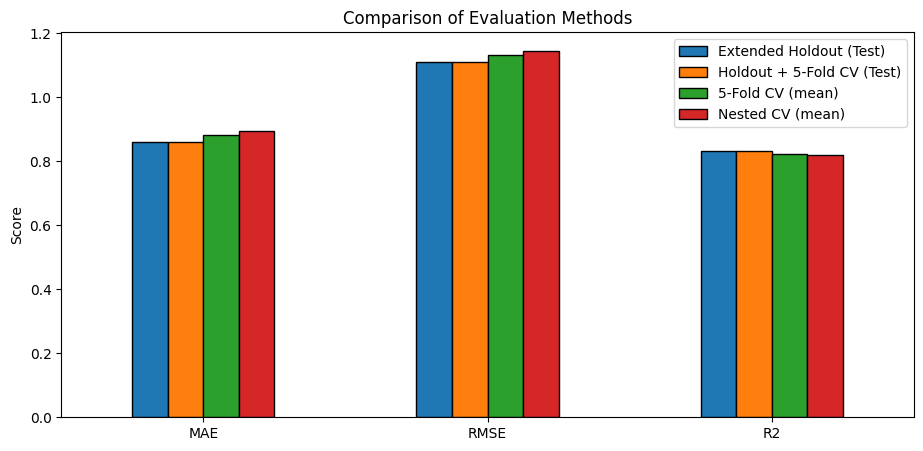

In [39]:
summary_df.T.plot(kind='bar', edgecolor='black', figsize=(11, 5))
plt.title('Comparison of Evaluation Methods')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='upper right')
plt.grid(False)
plt.show()

## Συμπεράσματα

- Όλες οι μέθοδοι δίνουν σχεδόν ίδια αποτελέσματα: MAE ≈ 0.86-0.89, RMSE ≈ 1.11-1.15 και R² ≈ 0.82-0.83.
- Το R² ≈ 0.82 σημαίνει ότι το μοντέλο εξηγεί περίπου το 82% της διακύμανσης του σκορ κούρασης, άρα είναι πολύ καλύτερο από το να προβλέπουμε πάντα τη μέση τιμή.
- Όλες οι μέθοδοι κατέληξαν στον ίδιο συνδυασμό (k = 15 με distance), άρα η επιλογή είναι σταθερή.
- Extended Holdout: το πιο γρήγορο, αλλά βασίζεται σε ένα μόνο validation και test set.
- Holdout + CV και Nested CV: πιο αξιόπιστα, γιατί η επιλογή γίνεται με μέσο όρο πολλών folds. Το Nested CV είναι το πιο αμερόληπτο, αλλά και το πιο αργό, και δίνει την πιο συντηρητική εκτίμηση.
- Σε σύγκριση με το Μέρος Ι, η παλινδρόμηση δίνει περισσότερη πληροφορία: αντί για μια κατηγορία, προβλέπουμε πόσο κουρασμένος θα είναι ο χρήστης.